#  Goal: build a model to predict whether a peptide is an activator or not in plant tissue.

In [1]:
import os
!pip install scikit-learn
!pip install xgboost
!pip install shap
os.chdir("../")
os.makedirs("outputs", exist_ok=True)

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


## Prepare the data

In [2]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from tqdm import tqdm, notebook

# Use the cores Slurm allocated, falling back to every core on the machine
n_cpus = int(os.environ.get('SLURM_CPUS_PER_TASK', os.cpu_count()))

# Output files will include this label
notebook_title = 'XGBoost_tiles_full_CV'

# this is to set up the figure style
plt.style.use('default')
mpl.rcParams['font.size']= 7
mpl.rcParams["svg.fonttype"] = "none"# to save text as actual text rather than vectorized shapes
mpl.rcParams['axes.linewidth'] = 0.5
mpl.rcParams['xtick.major.width'] = 0.5
mpl.rcParams['ytick.major.width'] = 0.5
mpl.rcParams['xtick.minor.width'] = 0.5
mpl.rcParams['ytick.minor.width'] = 0.5

%matplotlib inline
%config InlineBackend.figure_formats = ['svg']

First, we load the data.

The first file contains all of the features we will use as inputs and the mean measured activation values in both yeast and plants.

The second file tells us how far apart the n=2 replicates were for each peptide, information we will use to separate the means back into their original observed values.

In [3]:
df_tf = pd.read_csv('handoffs/Anya_plant_TF_all_data_annotated_features.csv')
residuals = pd.read_csv('handoffs/all_data_6_2026_relaxed_with_residual.csv')

id_col = '#Feature'
target_plant = 'z_log_enrichment_mean'
target_yeast = 'PADI Score'

# Sort the two dataframes so they can recombine cleanly
df_tf = df_tf.sort_values(id_col)
residuals = residuals.sort_values(id_col)

# Downstream operations look at target, so we can choose what we model here
target = target_plant

original_features = list(
    df_tf.columns[df_tf.columns.get_loc('tile_context_disorder'):-1]
)

# residuals contains data for peptides not in df_tf
# Here we remove extraneous peptides and zip the two dataframes together
df_tf['replicate_residual_abs'] = residuals[residuals[id_col].isin(df_tf[id_col])]['replicate_residual_abs']

original_features

['tile_context_disorder',
 'frac_A',
 'frac_C',
 'frac_D',
 'frac_E',
 'frac_F',
 'frac_G',
 'frac_H',
 'frac_I',
 'frac_K',
 'frac_L',
 'frac_M',
 'frac_N',
 'frac_P',
 'frac_Q',
 'frac_R',
 'frac_S',
 'frac_T',
 'frac_V',
 'frac_W',
 'frac_Y',
 'frac_pos',
 'frac_neg',
 'frac_polar',
 'frac_nonpolar',
 'frac_hydrophobic',
 'frac_aliphatic',
 'frac_aromatic',
 'frac_charged',
 'charge_density',
 'mean_hydrophobicity',
 'tile_intrinsic_disorder',
 'kappa',
 'aliphatic_clustering',
 'aromatic_clustering',
 'positive_clustering',
 'negative_clustering',
 'charged_clustering',
 'polar_uncharged_clustering',
 'mean_helix_propensity',
 'max_hmoment',
 'max_hmoment_mean_hydro',
 'max_hmoment_start',
 'aa_entropy',
 'XX_AA',
 'XX_AC',
 'XX_AD',
 'XX_AE',
 'XX_AF',
 'XX_AG',
 'XX_AH',
 'XX_AI',
 'XX_AK',
 'XX_AL',
 'XX_AM',
 'XX_AN',
 'XX_AP',
 'XX_AQ',
 'XX_AR',
 'XX_AS',
 'XX_AT',
 'XX_AV',
 'XX_AW',
 'XX_AY',
 'XX_CA',
 'XX_CC',
 'XX_CD',
 'XX_CE',
 'XX_CF',
 'XX_CG',
 'XX_CH',
 'XX_CI',
 '

The data are not completely clean, so we need to remove any rows and columns that will compromise downstream modeling. That mostly means getting rid of rows/columns with NaN values in them, but it also means removing peptides active in yeast, since we are trying to judge what features differentiate a non-activator from a plant-only activator.

In [4]:
print(df_tf.shape)

# Remove any line that is missing either target or replicate information
df_tf = df_tf[~(df_tf[target_plant].isna())]
df_tf = df_tf[~(df_tf[target_yeast].isna())]
df_tf = df_tf[~(df_tf['replicate_residual_abs'].isna())]
print(df_tf.shape)

# Print all features that contain nans, for scrutiny
print(df_tf.columns[df_tf.isna().any()].tolist())

# Remove features that contain nans
df_tf = df_tf.dropna(axis=1)
print(df_tf.shape)

# ART demands this later
df_tf = df_tf.rename(columns = {id_col: 'Line Name'})
id_col = 'Line Name'

# Remove peptides with excessive measurement variance
df_tf = df_tf[df_tf['replicate_residual_abs'] < 1]
print(df_tf.shape)

# Remove from original_features any features that were deleted here
original_features = [
    feature
    for feature in original_features
    if feature in df_tf.columns and pd.api.types.is_numeric_dtype(df_tf[feature])
]
len(original_features)

(12660, 968)
(11890, 968)
['aliphatic_clustering', 'aromatic_clustering', 'positive_clustering', 'negative_clustering', 'charged_clustering', 'polar_uncharged_clustering']
(11890, 962)
(11370, 962)


956

We will set aside 20% of data per cross-validation fold, chosen at random and keeping replicates together, so that we can properly judge our model at the end of this pipeline.

Since we know the difference between the high and low measurements, we can simply add half the difference and subtract half the difference from the mean to get the original high and low values respectively.

In [5]:
all_data = df_tf

all_data['enrichment_low'] = all_data[target_plant] - all_data['replicate_residual_abs'] / 2
all_data['enrichment_high'] = all_data[target_plant] + all_data['replicate_residual_abs'] / 2
all_data

,Unnamed: 0,Line Name,z_log_enrichment_mean,quality,tile_context_disorder,frac_A,frac_C,frac_D,frac_E,frac_F,...,max_run1gap_R,max_run1gap_S,max_run1gap_T,max_run1gap_V,max_run1gap_W,max_run1gap_Y,PADI Score,replicate_residual_abs,enrichment_low,enrichment_high
0,0,AT1G01010.1_161,0.233863,neutral,0.829148,0.100,0.000,0.050,0.000,0.025,...,3.0,3.0,2.0,3.0,1.0,2.0,-0.218857,0.430366,0.018680,0.449046
1,1,AT1G01010.1_181,-0.142936,neutral,0.898990,0.050,0.000,0.025,0.050,0.025,...,3.0,3.0,2.0,3.0,1.0,2.0,-0.702189,0.268999,-0.277436,-0.008437
3,3,AT1G01010.1_221,1.355938,activator,0.656785,0.050,0.000,0.075,0.025,0.050,...,1.0,2.0,1.0,2.0,2.0,2.0,5.023688,0.261223,1.225326,1.486549
4,4,AT1G01010.1_241,0.900008,activator,0.190468,0.025,0.000,0.050,0.150,0.050,...,1.0,2.0,1.0,2.0,2.0,2.0,5.071580,0.144587,0.827715,0.972302
5,5,AT1G01010.1_261,0.073774,neutral,0.523285,0.000,0.000,0.050,0.175,0.050,...,2.0,2.0,2.0,2.0,2.0,2.0,1.025454,0.389276,-0.120864,0.268411
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12654,12654,AT3G11450.1_591,-0.131940,neutral,0.180660,0.125,0.025,0.000,0.075,0.025,...,2.0,2.0,2.0,2.0,2.0,1.0,-0.505418,0.765514,-0.514696,0.250817
12655,12655,AT3G11450.1_607,0.023380,neutral,0.286625,0.100,0.025,0.000,0.100,0.025,...,2.0,2.0,2.0,2.0,2.0,1.0,-0.454887,0.682346,-0.317793,0.364553
12656,12656,AT3G11580.1_1,-0.015231,neutral,0.906015,0.050,0.000,0.050,0.050,0.025,...,2.0,2.0,2.0,2.0,1.0,2.0,3.122846,0.085437,-0.057949,0.027488
12657,12657,AT3G11580.1_101,-0.790350,ambiguous_repressor,0.178930,0.025,0.000,0.100,0.000,0.100,...,3.0,2.0,2.0,3.0,2.0,2.0,-0.284669,0.164196,-0.872448,-0.708252


Here, we will create two copies of all_data, one with the high values and one with the low values, so we can then stack them together and create our final training data set with both replicates represented. We do not do the same with the test data since our overall goal is to predict the labels, and those are based on the mean.

In [6]:
df_high = all_data[original_features]
df_high.insert(0, target_plant, all_data['enrichment_high'])
df_high.insert(0, id_col, all_data[id_col])

df_low = all_data[original_features]
df_low.insert(0, target_plant, all_data['enrichment_low'])
df_low.insert(0, id_col, all_data[id_col])

all_data = pd.concat([df_high, df_low], axis=0)
all_data

,Line Name,z_log_enrichment_mean,tile_context_disorder,frac_A,frac_C,frac_D,frac_E,frac_F,frac_G,frac_H,...,max_run1gap_M,max_run1gap_N,max_run1gap_P,max_run1gap_Q,max_run1gap_R,max_run1gap_S,max_run1gap_T,max_run1gap_V,max_run1gap_W,max_run1gap_Y
0,AT1G01010.1_161,0.449046,0.829148,0.100,0.000,0.050,0.000,0.025,0.050,0.000,...,2.0,2.0,3.0,2.0,3.0,3.0,2.0,3.0,1.0,2.0
1,AT1G01010.1_181,-0.008437,0.898990,0.050,0.000,0.025,0.050,0.025,0.075,0.025,...,2.0,3.0,1.0,3.0,3.0,3.0,2.0,3.0,1.0,2.0
3,AT1G01010.1_221,1.486549,0.656785,0.050,0.000,0.075,0.025,0.050,0.075,0.025,...,1.0,2.0,2.0,4.0,1.0,2.0,1.0,2.0,2.0,2.0
4,AT1G01010.1_241,0.972302,0.190468,0.025,0.000,0.050,0.150,0.050,0.025,0.025,...,2.0,2.0,2.0,4.0,1.0,2.0,1.0,2.0,2.0,2.0
5,AT1G01010.1_261,0.268411,0.523285,0.000,0.000,0.050,0.175,0.050,0.000,0.075,...,2.0,2.0,2.0,3.0,2.0,2.0,2.0,2.0,2.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12654,AT3G11450.1_591,-0.514696,0.180660,0.125,0.025,0.000,0.075,0.025,0.025,0.000,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0
12655,AT3G11450.1_607,-0.317793,0.286625,0.100,0.025,0.000,0.100,0.025,0.050,0.000,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0
12656,AT3G11580.1_1,-0.057949,0.906015,0.050,0.000,0.050,0.050,0.025,0.025,0.150,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0
12657,AT3G11580.1_101,-0.872448,0.178930,0.025,0.000,0.100,0.000,0.100,0.075,0.075,...,1.0,1.0,1.0,2.0,3.0,2.0,2.0,3.0,2.0,2.0


Since we are working with replicates (n=2), we need to be able to keep track of which instances come from the same peptide. We don't want the replicates to ever occur on opposite side of a cross validation fold, since that would leak data and give us an artificially high score. We achieve this by adding a 'group' column unique to each peptide and giving the Line Name column tags for replicate 1 and replicate 2.

In [7]:
def label_replicates(column):
    accum = []
    for value in column:
        num = 1
        value_tagged = f'{value}-R{num}'
        while value_tagged in accum:
            num += 1
            value_tagged = f'{value}-R{num}'
        accum.append(value_tagged)
    return accum 

In [8]:
all_data = all_data.reset_index()
all_data.insert(2, 'group', all_data[id_col])
all_data[id_col] = label_replicates(all_data[id_col])

_non_feature = {id_col, 'Line Name', target, 'group', 'index', 'level_0'}
original_features = [
    c for c in all_data.columns
    if c not in _non_feature and pd.api.types.is_numeric_dtype(all_data[c])
]

all_data

,index,Line Name,group,z_log_enrichment_mean,tile_context_disorder,frac_A,frac_C,frac_D,frac_E,frac_F,...,max_run1gap_M,max_run1gap_N,max_run1gap_P,max_run1gap_Q,max_run1gap_R,max_run1gap_S,max_run1gap_T,max_run1gap_V,max_run1gap_W,max_run1gap_Y
0,0,AT1G01010.1_161-R1,AT1G01010.1_161,0.449046,0.829148,0.100,0.000,0.050,0.000,0.025,...,2.0,2.0,3.0,2.0,3.0,3.0,2.0,3.0,1.0,2.0
1,1,AT1G01010.1_181-R1,AT1G01010.1_181,-0.008437,0.898990,0.050,0.000,0.025,0.050,0.025,...,2.0,3.0,1.0,3.0,3.0,3.0,2.0,3.0,1.0,2.0
2,3,AT1G01010.1_221-R1,AT1G01010.1_221,1.486549,0.656785,0.050,0.000,0.075,0.025,0.050,...,1.0,2.0,2.0,4.0,1.0,2.0,1.0,2.0,2.0,2.0
3,4,AT1G01010.1_241-R1,AT1G01010.1_241,0.972302,0.190468,0.025,0.000,0.050,0.150,0.050,...,2.0,2.0,2.0,4.0,1.0,2.0,1.0,2.0,2.0,2.0
4,5,AT1G01010.1_261-R1,AT1G01010.1_261,0.268411,0.523285,0.000,0.000,0.050,0.175,0.050,...,2.0,2.0,2.0,3.0,2.0,2.0,2.0,2.0,2.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22735,12654,AT3G11450.1_591-R2,AT3G11450.1_591,-0.514696,0.180660,0.125,0.025,0.000,0.075,0.025,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0
22736,12655,AT3G11450.1_607-R2,AT3G11450.1_607,-0.317793,0.286625,0.100,0.025,0.000,0.100,0.025,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0
22737,12656,AT3G11580.1_1-R2,AT3G11580.1_1,-0.057949,0.906015,0.050,0.000,0.050,0.050,0.025,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0
22738,12657,AT3G11580.1_101-R2,AT3G11580.1_101,-0.872448,0.178930,0.025,0.000,0.100,0.000,0.100,...,1.0,1.0,1.0,2.0,3.0,2.0,2.0,3.0,2.0,2.0


In [9]:
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)
outer_cv_folds = list(gkf.split(all_data[original_features], None, groups=all_data['group']))

## Modeling: Use an ensemble of XGBoost regressors

XGBoost regressors train an ensemble of decision trees, each using a subset of the features and a subset of the instances, providing a robust overall model for predicting unseen values.

In [10]:
from sklearn.metrics import r2_score, roc_curve
from sklearn.model_selection import GridSearchCV
from xgboost.sklearn import XGBRegressor

To get the best model possible, while ensuring we get effective extrapolation, we will perform a GridSearchCV to pick our XGBoost paramters. This means we will train models on 80% of the training data and predict on 20% until all data have been in the 20%. We score the out-of-fold predictions on the 20% and whatever parameters give the best score, we will use those going forward.

In [11]:
%%time

grid_search_results = []

for train_index, test_index in outer_cv_folds:

    df_tf = all_data.iloc[train_index]
    
    X_train = df_tf[original_features]
    y_train = df_tf[target]
    
    gkf = GroupKFold(n_splits=5)
    # GridSearchCV sends itself to the worker processes, so cv must be picklable (not a generator)
    folds = list(gkf.split(X_train, None, groups=df_tf['group']))
    
    xgb = XGBRegressor(objective="reg:squarederror",
                       learning_rate=0.01,
                       random_state=3,
                       n_jobs=1)
    
    param_grid = {
        "n_estimators": [200, 400, 600, 800, 1000],
        "max_depth": [3, 5, 7, 9],
        "subsample": [0.6, 0.7, 0.8, 0.9],
        "colsample_bytree": [0.6, 0.7, 0.8, 0.9],
    }
    
    grid_search = GridSearchCV(
        estimator=xgb,
        param_grid=param_grid,
        scoring="neg_root_mean_squared_error",
        cv=folds,
        n_jobs=n_cpus,
        verbose=1,
    )
    
    grid_search.fit(X_train, y_train)
    grid_search_results.append(grid_search)

Fitting 5 folds for each of 320 candidates, totalling 1600 fits
Fitting 5 folds for each of 320 candidates, totalling 1600 fits
Fitting 5 folds for each of 320 candidates, totalling 1600 fits
Fitting 5 folds for each of 320 candidates, totalling 1600 fits
Fitting 5 folds for each of 320 candidates, totalling 1600 fits
CPU times: user 5min 30s, sys: 8.39 s, total: 5min 39s
Wall time: 1h 10min 41s


Here we will check what the best model's parameters and cross-validated RMSE are, while also checking (but not using for anything) how well it generalizes to the completely unseen test data not used in this process.

In [12]:
from sklearn.metrics import mean_squared_error

for indices, grid_search in zip(outer_cv_folds, grid_search_results):

    train_index, test_index = indices

    df_withheld = all_data.iloc[test_index]

    print("Best params:", grid_search.best_params_)
    print("Best CV RMSE:", -grid_search.best_score_)
    
    X_test = df_withheld[original_features]
    y_test = df_withheld[target]
    
    best_model = grid_search.best_estimator_
    preds = best_model.predict(X_test)
    test_rmse = mean_squared_error(y_test, preds)
    print("Test RMSE:", test_rmse)
    print("\n\n")

Best params: {'colsample_bytree': 0.7, 'max_depth': 9, 'n_estimators': 1000, 'subsample': 0.6}
Best CV RMSE: 0.6746771628503293
Test RMSE: 0.40525340643605096



Best params: {'colsample_bytree': 0.8, 'max_depth': 7, 'n_estimators': 1000, 'subsample': 0.6}
Best CV RMSE: 0.6664693265744143
Test RMSE: 0.43005295342764244



Best params: {'colsample_bytree': 0.9, 'max_depth': 9, 'n_estimators': 1000, 'subsample': 0.6}
Best CV RMSE: 0.6673016230377469
Test RMSE: 0.4299161012668913



Best params: {'colsample_bytree': 0.7, 'max_depth': 9, 'n_estimators': 1000, 'subsample': 0.6}
Best CV RMSE: 0.6642110409434449
Test RMSE: 0.44735952503852666



Best params: {'colsample_bytree': 0.7, 'max_depth': 7, 'n_estimators': 1000, 'subsample': 0.6}
Best CV RMSE: 0.6600283028600801
Test RMSE: 0.48417489246434214





The model_pool class will let us use multiple models in an ensemble, such that each model predicts on a given input and the pool returns the mean prediction across all loaded models.

In [13]:
class model_pool:
    def __init__(self, estimators):
        self.estimators = estimators

    def predict(self, X):
        preds = [estimator.predict(X) for estimator in self.estimators]
        means = np.mean(preds, axis=0)
        return means

    def fit(self, X, y):
        for estimator in self.estimators:
            estimator.fit(X, y)

Because these data contain a great deal of uncertainty, we will hedge against that uncertainty by training a small ensemble of models and averaging their predictions. For simplicity, we will use the same data splits as we used in the GridSearchCV above, training one model per CV fold to keep.

In [14]:
model_pools = []

all_data['y_pred'] = np.nan  # Avoid problem writing to nonexistent column

for indices, grid_search in zip(outer_cv_folds, grid_search_results):
    
    train_index, test_index = indices

    df_tf = all_data.iloc[train_index]
    df_withheld = all_data.iloc[test_index]

    xgb_pool = []
    
    X_train = df_tf[original_features]
    X_test = df_withheld[original_features]
    
    gkf = GroupKFold(n_splits=5)
    inner_cv_folds = gkf.split(X_train, None, groups=df_tf['group'])
    
    for train_idx, test_idx in inner_cv_folds:
        fold_X_train = df_tf.iloc[train_idx][original_features]
        fold_y_train = df_tf.iloc[train_idx][target]
        
        xgb = XGBRegressor(objective="reg:squarederror",
                           learning_rate=0.01,
                           random_state=3,
                           n_jobs=n_cpus,
                           **grid_search.best_params_)
        
        xgb.fit(fold_X_train, fold_y_train)
        xgb_pool.append(xgb)
    pool = model_pool(xgb_pool)
    model_pools.append(pool)
    preds = pool.predict(X_test)
    all_data.loc[test_index, 'y_pred'] = preds
all_data

,index,Line Name,group,z_log_enrichment_mean,tile_context_disorder,frac_A,frac_C,frac_D,frac_E,frac_F,...,max_run1gap_N,max_run1gap_P,max_run1gap_Q,max_run1gap_R,max_run1gap_S,max_run1gap_T,max_run1gap_V,max_run1gap_W,max_run1gap_Y,y_pred
0,0,AT1G01010.1_161-R1,AT1G01010.1_161,0.449046,0.829148,0.100,0.000,0.050,0.000,0.025,...,2.0,3.0,2.0,3.0,3.0,2.0,3.0,1.0,2.0,-0.082900
1,1,AT1G01010.1_181-R1,AT1G01010.1_181,-0.008437,0.898990,0.050,0.000,0.025,0.050,0.025,...,3.0,1.0,3.0,3.0,3.0,2.0,3.0,1.0,2.0,0.137392
2,3,AT1G01010.1_221-R1,AT1G01010.1_221,1.486549,0.656785,0.050,0.000,0.075,0.025,0.050,...,2.0,2.0,4.0,1.0,2.0,1.0,2.0,2.0,2.0,0.566304
3,4,AT1G01010.1_241-R1,AT1G01010.1_241,0.972302,0.190468,0.025,0.000,0.050,0.150,0.050,...,2.0,2.0,4.0,1.0,2.0,1.0,2.0,2.0,2.0,0.973956
4,5,AT1G01010.1_261-R1,AT1G01010.1_261,0.268411,0.523285,0.000,0.000,0.050,0.175,0.050,...,2.0,2.0,3.0,2.0,2.0,2.0,2.0,2.0,2.0,0.134545
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22735,12654,AT3G11450.1_591-R2,AT3G11450.1_591,-0.514696,0.180660,0.125,0.025,0.000,0.075,0.025,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,-0.337647
22736,12655,AT3G11450.1_607-R2,AT3G11450.1_607,-0.317793,0.286625,0.100,0.025,0.000,0.100,0.025,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,-0.515750
22737,12656,AT3G11580.1_1-R2,AT3G11580.1_1,-0.057949,0.906015,0.050,0.000,0.050,0.050,0.025,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,-0.302800
22738,12657,AT3G11580.1_101-R2,AT3G11580.1_101,-0.872448,0.178930,0.025,0.000,0.100,0.000,0.100,...,1.0,1.0,2.0,3.0,2.0,2.0,3.0,2.0,2.0,-0.668831


Looking at an ROC curve can tell us how well the regressor we have trained here performs as a classifier. Since the original objective was to predict whether a peptide is/isn't an activator, this brings us back to our original goal. The higher the AUC is, the better the model is performing, with 0.5 being no better than random chance and 1.0 being perfect.

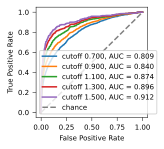

In [21]:
from sklearn.metrics import roc_curve, auc

activator_threshold_values = np.linspace(0.7, 1.5, 5)
# original threshold was 0.823, the average across libraries

fig = plt.figure()
fig.set_size_inches(2, 2)
for activator_threshold in activator_threshold_values:
    test_labels = (np.array(all_data[target]) >= activator_threshold).astype(int)
    fpr, tpr, _ = roc_curve(test_labels, all_data['y_pred'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr,tpr,label=f"cutoff {activator_threshold:.3f}, AUC = {roc_auc:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.savefig(f'outputs/{notebook_title}_classifier_ROC.svg')

For bookeeping, we calculate classifier performance metrics for our classifier using a threshold of 0.83, which is the average activator cutoff across datasets. We saw from the AUC curves that performance improves with threshold stringency, but let's use a single threshold value for now.


In [16]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score

activator_threshold = 0.83

y_true = (all_data[target] >= activator_threshold).astype(int)
y_pred = (all_data['y_pred'] >= activator_threshold).astype(int)
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
performance_df = pd.DataFrame([{
            "accuracy": accuracy_score(y_true, y_pred),
            "precision_class_0": precision[0],
            "recall_class_0": recall[0],
            "f1_class_0": f1[0],
            "precision_class_1": precision[1],
            "recall_class_1": recall[1],
            "f1_class_1": f1[1],
            "auc": roc_auc_score(y_true, all_data['y_pred'])}])

metrics_path = f'outputs/{notebook_title}_classifier_metrics.csv'
performance_df.to_csv(metrics_path, index=False)
performance_df


,accuracy,precision_class_0,recall_class_0,f1_class_0,precision_class_1,recall_class_1,f1_class_1,auc
0,0.937027,0.942893,0.992227,0.966931,0.69403,0.226829,0.341912,0.829927


Finally, we can use SHAP to determine how much each feature contributes to the final score given to each predicted value. 

In [17]:
import shap
from joblib import Parallel, delayed

def explain_fold(pool, X, n_threads):
    # Split the cores between the folds running in parallel
    for estimator in pool.estimators:
        estimator.set_params(n_jobs=n_threads)
    explainer = shap.Explainer(pool.predict, X.sample(100), max_evals=2000)
    return explainer(X)

fold_inputs = []

for indices, pool in zip(outer_cv_folds, model_pools):

    train_index, test_index = indices
    df_withheld = all_data.iloc[test_index]
    X = df_withheld[original_features].drop_duplicates()

    fold_inputs.append((pool, X))

n_folds = len(fold_inputs)
shap_outputs = Parallel(n_jobs=min(n_folds, n_cpus))(
    delayed(explain_fold)(pool, X, max(1, n_cpus // n_folds))
    for pool, X in fold_inputs
)

PermutationExplainer explainer: 2275it [1:21:43,  2.16s/it]                          
PermutationExplainer explainer: 2275it [1:22:01,  2.17s/it]                          
PermutationExplainer explainer: 2275it [1:32:01,  2.43s/it]                          
PermutationExplainer explainer: 2275it [1:32:29,  2.44s/it]                          
PermutationExplainer explainer: 2275it [1:32:56,  2.45s/it]                          


Looking at how well predictions and observations align, we can observe that, while this model does a decent job of assigning activator/non-activator labels, its ability to predict the precise enrichment score of a given peptide is limited.

In [18]:
r2 = r2_score(all_data[target], all_data['y_pred'])

fig = plt.figure()
fig.set_size_inches(2, 2)
plt.scatter(all_data[target], all_data['y_pred'], s=2)
plt.xlabel('Observations')
plt.ylabel('Predictions')
plt.title(f'r2 = {r2:0.3}')
plt.xlim(-5.1,5)
plt.ylim(-5.1,5)
plt.savefig(f'outputs/{notebook_title}_regressor.svg')

We gather all of the SHAP values across all 5 folds here so we can plot them together as one unified swarm plot.

In [19]:
from collections import namedtuple

pooled_shap_values = np.concatenate([shap.values for shap in shap_outputs])
pooled_shap_base_values = np.concatenate([shap.base_values for shap in shap_outputs])
pooled_shap_data = np.concatenate([shap.data for shap in shap_outputs])
shap_result = namedtuple('shap_value',
                         field_names=['values', 'base_values', 'data'])

pooled_shap = shap_result(pooled_shap_values,
                          pooled_shap_base_values,
                          pooled_shap_data)

In [20]:
from matplotlib.collections import PathCollection

SWARM_MAX_DISPLAY = 25
SWARM_CMAP = "magma"
SWARM_HEIGHT_SCALE = 1.75
figsize = (1.8, 1.8)
font_size = 7
marker_size = 5

if hasattr(pooled_shap, "values"):
    shap_for_plot = np.asarray(pooled_shap.values)
    X_for_plot = pd.DataFrame(pooled_shap.data, columns=X.columns)#, index=list(range(len(pooled_shap.base_values))))
else:
    shap_for_plot = np.asarray(pooled_shap)
    X_for_plot = X

shap.summary_plot(
    shap_for_plot,
    X_for_plot,
    plot_type="dot",
    cmap=SWARM_CMAP,
    plot_size=(figsize[0], figsize[1] * SWARM_HEIGHT_SCALE),
    max_display=SWARM_MAX_DISPLAY,
    show=False,
)

fig = plt.gcf()
for ax in fig.get_axes():
    ax.title.set_fontsize(font_size)
    ax.xaxis.label.set_fontsize(font_size)
    ax.yaxis.label.set_fontsize(font_size)
    ax.tick_params(axis="both", labelsize=font_size)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontsize(font_size)
    for text in ax.texts:
        text.set_fontsize(font_size)
    for collection in ax.collections:
        collection.set_rasterized(False)
        if isinstance(collection, PathCollection):
            collection.set_sizes([marker_size])

plt.savefig(f'outputs/{notebook_title}_shap.svg')
plt.show()

/global/home/users/jdtibochab/.local/lib/python3.12/site-packages/shap/plots/_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
